In [3]:
import numpy as np
import netCDF4 as nc
import xarray as xr
import os
import json
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.lines as mlines
from matplotlib.colors import TwoSlopeNorm
import pandas as pd
import cartopy.crs as ccrs
# from ladcp_tools import *                  # load_all_stations, ...
# from tools import *                        # setup_map, load_satellite, load_eddies, plot_eddies
from tools_eg import *

/Users/emmagurcan/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [4]:
EXTENT = None  # e.g. [10, 20, -42, -34]
lon_min, lon_max, lat_min, lat_max = 8, 25, -41, -34
extent = [lon_min, lon_max, lat_min, lat_max]

CRUISE_START = "2026-05-14"
CRUISE_END   = "2026-07-27"

ft = 10
# ADT colours: white exactly at 0, but each side stretched separately
# (ADT here is ~ -0.3 .. +1.5 m). Lower ADT_MIN -> darker cyclone blues,
# raise ADT_MAX -> fewer saturated anticyclone reds.
ADT_MIN, ADT_MAX = -0.3, 1.5
adt_norm = TwoSlopeNorm(vmin=ADT_MIN, vcenter=0, vmax=ADT_MAX)
levels = np.arange(ADT_MIN, ADT_MAX + 0.001, 0.02)
adt_ticks = [-0.3, 0, 0.3, 0.6, 0.9, 1.2, 1.5]

crs = ccrs.PlateCarree()
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max) / 2)


BASE = Path("/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS")
DIR_SADCP = BASE / "data/SADCP"
SADCP_FILES = {"OS150": DIR_SADCP / "WHIRLS_NB150_TOT_osite.nc",   # full cruise (README)
               "OS38": DIR_SADCP / "WHIRLS_BB38_TOT_osite.nc"}
DIR_LADCP = BASE / "data/LADCP/traitement_avec_SADCP"
DIR_SSH = BASE / "data/SSH"
DIR_EDDIES = {"TOEDDIES_better_ADT": BASE / "data/TOEDDIES/TOEDDIES_better_ADT",
              "TOEDDIES": BASE / "data/TOEDDIES/TOEDDIES"}
FNAME_BATHY = BASE / "data/bathymetry/etopo2.nc"
DIR_TRACKS = BASE / "figures/eddy_tracks"
DIR_CODE = BASE / "analysis"          # where ladcp_tools.py lives

DIR_DRIFTERS =  BASE / "data/DRIFTERS/drifters"
DIR_GEOJSON = BASE / "data/DRIFTERS/drifters_tracks.geojson"

DIR_MVP = BASE / "data/MVP_Data_processed"

# Animation
ANIM_START = "2026-07-01"                 # first drifter deployment
ANIM_END   = CRUISE_END                   # days without an ADT file are skipped
TAIL_DAYS  = 5                            # length of the track drawn behind each drifter (None = whole track)

# Drifter data: "csv" (folder of CSV snapshots, DIR_DRIFTERS) or "geojson" (DIR_GEOJSON)
DRIFTER_SOURCE = "csv"
FIRST_LAUNCH = "2026-07-01 05:00"         # fixes before this are bench tests (as in Solange's script)
FRAME_DIR = "whirls_drifters_animation"
OUT_MP4   = "whirls_drifters_animation.mp4"
FPS = 2                                   # frames (days) per second

os.makedirs(FRAME_DIR, exist_ok=True)

In [5]:
# ----------------------------------------------------------------------------
# Things loaded ONCE (they don't change from day to day)
# ----------------------------------------------------------------------------
# Bathymetry
bathymetry_data = xr.open_dataset(FNAME_BATHY)
lon_subset = bathymetry_data["lon"].sel(lon=slice(lon_min, lon_max))
lat_subset = bathymetry_data["lat"].sel(lat=slice(lat_min, lat_max))
depth_subset = bathymetry_data["topo"].sel(lon=slice(lon_min, lon_max),
                                           lat=slice(lat_min, lat_max))

# File lists
daily_ssh_files = sorted(os.listdir(DIR_SSH))
eddy_files_better = sorted(os.listdir(DIR_EDDIES['TOEDDIES_better_ADT']))
eddy_files_std = sorted(os.listdir(DIR_EDDIES['TOEDDIES']))

type_SADCP = "OS38"
sadcp = nc.Dataset(SADCP_FILES[type_SADCP])


In [6]:
transect = "Transect 14"
transect_path = f'/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/data/MVP_Data_processed/{transect}/'
out_dir = f'/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/figures/mvp/{transect}/'
if not os.path.isdir(out_dir):
    os.mkdir(out_dir)

In [7]:
files = sorted(Path(transect_path).glob("*.csv"))
dfs = []
for k, f in enumerate(files):
    df = pd.read_csv(f)
    df["CAST"] = k          # one processed CSV file = one MVP cast
    dfs.append(df)
mvp_trans = pd.concat(dfs, ignore_index=True)
print(len(files), "files")

100 files


In [8]:
sadcp_all = {}
for inst in ["OS150", "OS38"]:
    s = cascade_add_time(xr.open_dataset(SADCP_FILES[inst]))
    s = s.sortby("time")
    s = s.isel(time=~s.indexes["time"].duplicated())
    sadcp_all[inst] = sadcp_for_transect(mvp_trans, s)

sadcp_tr  = sadcp_all["OS150"]          # used for positions (and in the cell below)
sadcp_mvp = sadcp_on_mvp_times(mvp_trans, sadcp_tr, max_gap="30min")

mvp_trans["LON (°E)"] = mvp_trans["LON (°E)"].fillna(pd.Series(sadcp_mvp["LONGITUDE"].values, index=mvp_trans.index))
mvp_trans["LAT (°N)"] = mvp_trans["LAT (°N)"].fillna(pd.Series(sadcp_mvp["LATITUDE"].values, index=mvp_trans.index))

print("MVP samples without position:", mvp_trans["LAT (°N)"].isna().sum(), "of", len(mvp_trans))

MVP samples without position: 0 of 418500


In [9]:
# OS150 above Z_SPLIT (150 m), OS38 below: sadcp_window keeps the right depths for each
a = sadcp_window("OS150", sadcp=cascade_to_window_format(sadcp_all["OS150"], pgood_min=50))
b = sadcp_window("OS38",  sadcp=cascade_to_window_format(sadcp_all["OS38"],  pgood_min=50))
print("OS150:", len(a["time"]), "profiles,", a["z"].min(), "-", a["z"].max(), "m")
print("OS38: ", len(b["time"]), "profiles,", b["z"].min(), "-", b["z"].max(), "m")

# put both on the same time axis (both are 10-min means), then stack in depth
t = np.union1d(a["time"], b["time"])
def on_t(d, key):
    out = np.full((len(t),) + d[key].shape[1:], np.nan)
    out[np.searchsorted(t, d["time"])] = d[key]
    return out

lon_a, lat_a = on_t(a, "lon"), on_t(a, "lat")
sadcp_mvp_processed = dict(
    time=t,
    lon=np.where(np.isnan(lon_a), on_t(b, "lon"), lon_a),
    lat=np.where(np.isnan(lat_a), on_t(b, "lat"), lat_a),
    z=np.concatenate([a["z"], b["z"]]),
    u=np.concatenate([on_t(a, "u"), on_t(b, "u")], axis=1),
    v=np.concatenate([on_t(a, "v"), on_t(b, "v")], axis=1))
print(len(sadcp_mvp_processed["time"]), "SADCP profiles,",
      sadcp_mvp_processed["z"].min(), "-", sadcp_mvp_processed["z"].max(), "m")

Calculating Mean
  ! PGOOD_ADCP is all 0 in this file -> PGOOD mask skipped
Calculating Mean
OS150: 148 profiles, 24.260000228881836 - 144.25999450683594 m
OS38:  148 profiles, 167.4600067138672 - 983.4600219726562 m
148 SADCP profiles, 24.260000228881836 - 983.4600219726562 m


In [10]:
# ---------------- map background for the combined figure ----------------
out_dir = str(BASE / "figures/mvp") + f"/{transect}/"

date = pd.to_datetime(mvp_trans["TIME"]).median().strftime("%Y-%m-%d")
date_compact = date.replace("-", "")
ssh = load_satellite(DIR_SSH / [f for f in daily_ssh_files if date in f or date_compact in f][0])
eddy_files, eddy_source = get_eddy_files(date_compact, date)

edds = eddies_on_transect(eddy_files, mvp_trans["LON (°E)"].values, mvp_trans["LAT (°N)"].values)
print("eddies crossed:", [("C" if e["cyc"] else "AC") + f" ({e['dist_km']:.0f} km from track)" for e in edds])


eddies crossed: ['C (12 km from track)']


100 casts used


/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/analysis/tools_eg.py:1119: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = ax.pcolormesh(xkm, p, data, cmap=cmap, shading="nearest",


  C: Nencioli center at 272 km, outside section -> not marked


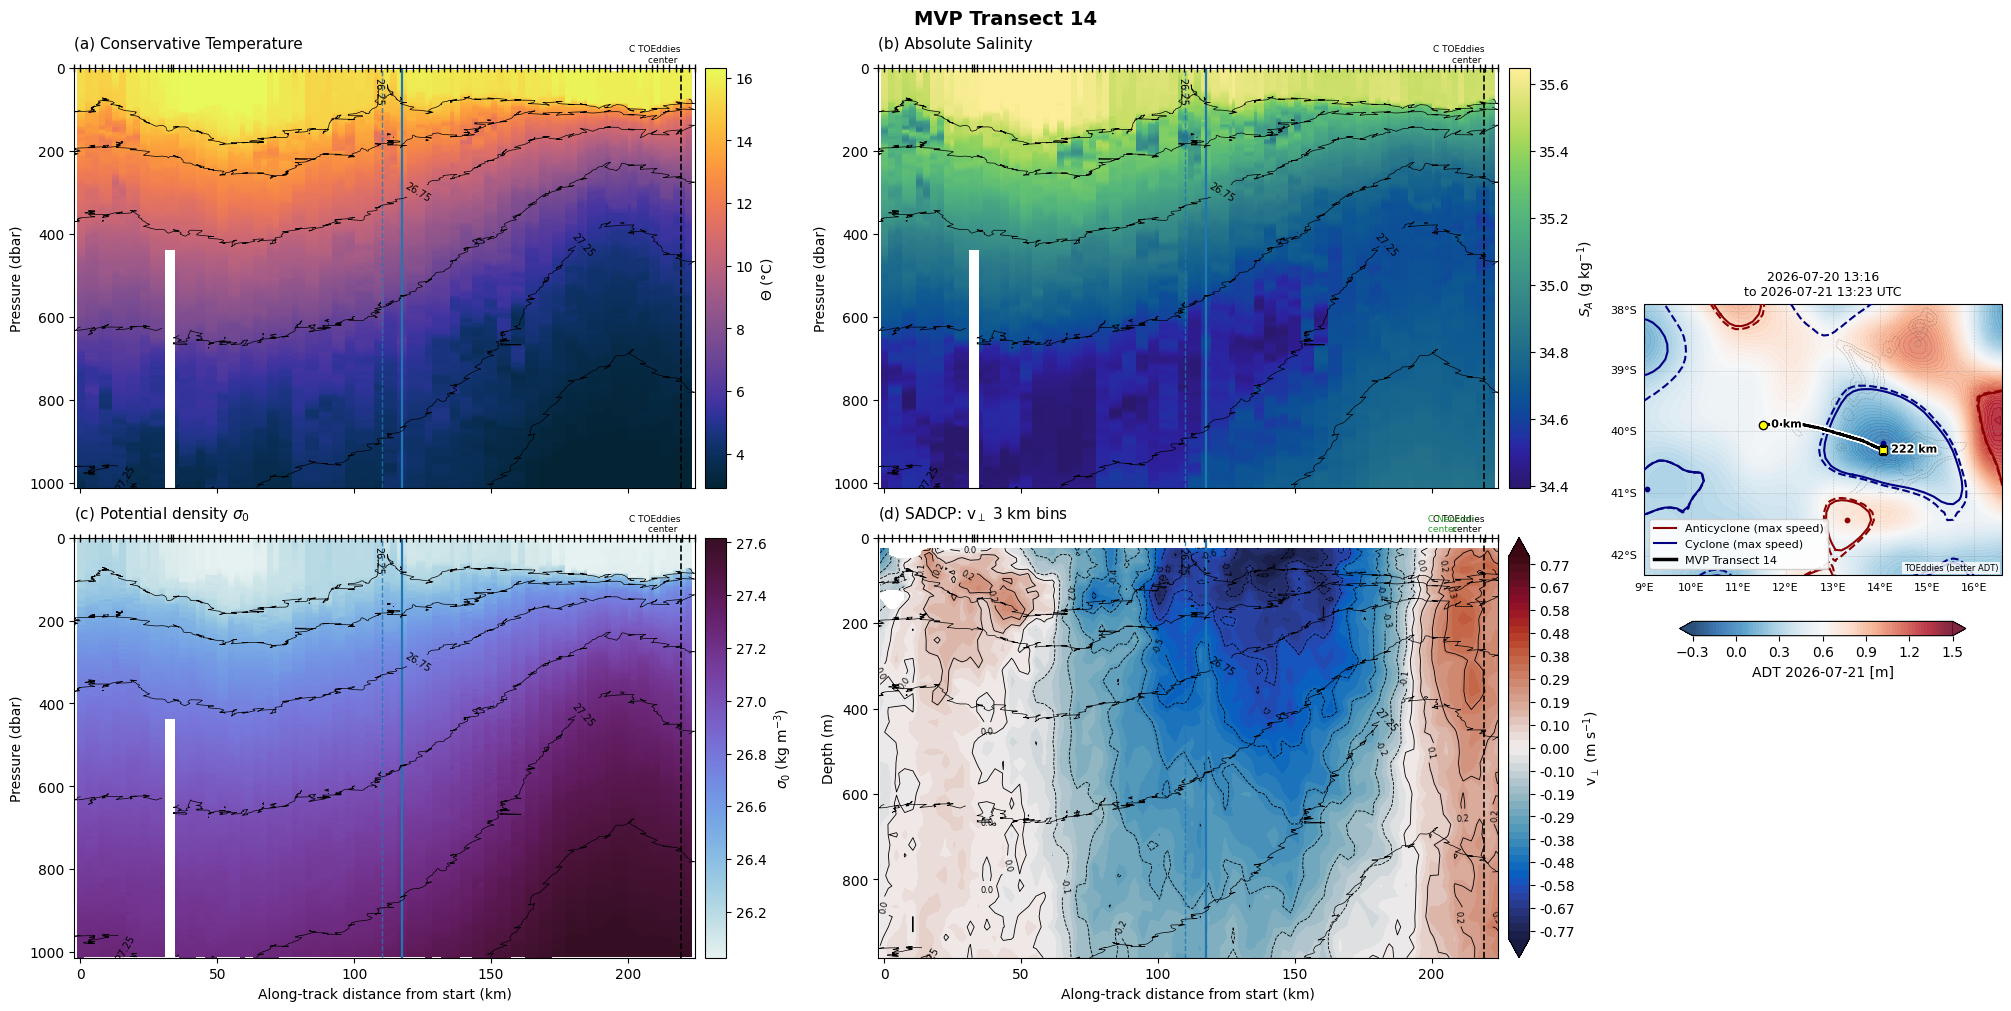

In [12]:
# ---------------- SADCP for zeta (PV) ----------------
ds = sadcp_tr                      # ADCP subset for this transect (sadcp_mvp is ~1 GB, not needed)
zdim = ds["depth"].dims[0]
u = ds["UVEL_ADCP_CORTIDE"].transpose("time", zdim).values
v = ds["VVEL_ADCP_CORTIDE"].transpose("time", zdim).values
pg = ds["PGOOD_ADCP"].transpose("time", zdim).values

u[pg < 50] = np.nan
v[pg < 50] = np.nan

args = [ssh, eddy_files, transect, eddy_source, adt_ticks, date, levels]
invert_x = True
if transect == "Transect 13" or transect == "Transect 14":
    sadcp_mvp_processed["u"] = -sadcp_mvp_processed["u"]
    sadcp_mvp_processed["v"] = -sadcp_mvp_processed["v"]
    invert_x = False
# ---------------- map + Theta / S_A / sigma0 ----------------
sec, fig, axs = process_transect(
    mvp_trans, adcp=sadcp_mvp_processed, cast_col="CAST",
    map_draw=draw_background,      # map_extent=extent  -> whole region instead of zoom
    map_args = args,
    title=f"MVP {transect}",
    eddy=edds,
    savepath=out_dir + f"{transect}_section_hydro_adcp",
    flip_x = invert_x,
    vel_lim = 0.8)
plt.show()

In [13]:
# ---------------- CTD background profile: casts outside every TOEddies contour ----------------
# Casts selected by whirls_ctd_outside_eddies.py (outside_eddies == True in the CSV).
import warnings
DIR_CTD = BASE / "data/CTD"
MD_CTD_NC = DIR_CTD / "ctd_metadata.nc"
CLASS_CSV = DIR_CTD / "ctd_toeddies_classification.csv"
PROFILE_EXT = (".nc", ".cnv", ".csv")   # preferred profile format first
REF_DP = 1.0                            # dbar, same bins as the MVP section
REF_MIN_N = 3                           # keep only pressure levels with >= this many casts

NAMES = {"p": ["prDM", "prdM", "prSM", "pr", "PRES", "pres", "pressure", "PRESSURE"],
         "t": ["t090C", "t068C", "t190C", "TEMP", "temp", "temperature", "TEMPERATURE"],
         "s": ["sal00", "sal11", "PSAL", "psal", "salinity", "SALINITY"]}
STD_NAMES = {"p": "sea_water_pressure", "t": "sea_water_temperature",
             "s": "sea_water_practical_salinity"}


def _txt(v):
    return v.decode().strip() if isinstance(v, bytes) else str(v).strip()


def find_profile_file(name):
    """Profile file of one cast under DIR_CTD, from the metadata 'file' entry."""
    stem = Path(name).stem
    hits = [f for f in DIR_CTD.rglob(f"{stem}*") if f.suffix.lower() in PROFILE_EXT
            and f.resolve() != MD_CTD_NC.resolve()]
    if not hits:
        return None
    hits.sort(key=lambda f: (PROFILE_EXT.index(f.suffix.lower()), f.stem != stem, len(f.name)))
    return hits[0]


def _pick(cols, key, std=None):
    for n in NAMES[key]:
        if n in cols:
            return n
    low = {c.lower(): c for c in cols}
    for n in NAMES[key]:
        if n.lower() in low:
            return low[n.lower()]
    return std


def read_cnv(path):
    names, rows, bad, in_data = [], [], -9.990e-29, False
    with open(path, errors="ignore") as f:
        for line in f:
            if in_data:
                parts = line.split()
                if len(parts) == len(names):
                    rows.append(parts)
            elif line.startswith("# name"):
                names.append(line.split("=", 1)[1].split(":")[0].strip())
            elif line.startswith("# bad_flag"):
                bad = float(line.split("=")[1])
            elif line.startswith("*END*"):
                in_data = True
    df = pd.DataFrame(np.asarray(rows, float), columns=names)
    return df.mask(np.isclose(df, bad))


def read_ctd_profile(path):
    """-> p (dbar), in-situ T, practical S of one cast (downcast only)."""
    suf = path.suffix.lower()
    if suf == ".nc":
        ds = xr.open_dataset(path)
        cols = list(ds.variables)
        by_std = {k: next((v for v in cols if ds[v].attrs.get("standard_name") == s), None)
                  for k, s in STD_NAMES.items()}
        names = {k: _pick(cols, k, by_std[k]) for k in "pts"}
        if None in names.values():
            raise KeyError(f"{path.name}: no pressure/temperature/salinity among {cols}")
        p, t, s = (np.asarray(ds[names[k]].values, float).squeeze() for k in "pts")
        ds.close()
    else:
        df = read_cnv(path) if suf == ".cnv" else pd.read_csv(path)
        names = {k: _pick(list(df.columns), k) for k in "pts"}
        if None in names.values():
            raise KeyError(f"{path.name}: no pressure/temperature/salinity among {list(df.columns)}")
        p, t, s = (df[names[k]].to_numpy(float) for k in "pts")
    if p.ndim != 1:
        raise ValueError(f"{path.name}: pressure is {p.ndim}-D, expected one profile per file")
    imax = int(np.nanargmax(p))                    # downcast: surface -> deepest point
    return p[:imax + 1], t[:imax + 1], s[:imax + 1], names


def bin_on_grid(p, val, p_edges):
    idx = np.digitize(p, p_edges) - 1
    ok = (idx >= 0) & (idx < len(p_edges) - 1) & np.isfinite(val)
    s = np.bincount(idx[ok], val[ok], minlength=len(p_edges) - 1)
    n = np.bincount(idx[ok], minlength=len(p_edges) - 1)
    with np.errstate(invalid="ignore"):
        return np.where(n > 0, s / n, np.nan)


# ---- casts used for the background ----
USE_ALL_CASTS = True          # False -> only the casts outside every TOEddies contour

cls = pd.read_csv(CLASS_CSV, parse_dates=["time"])
ref_casts = (cls if USE_ALL_CASTS else cls[cls["outside_eddies"]]).reset_index(drop=True)
md = xr.open_dataset(MD_CTD_NC)
md_file = [_txt(v) for v in np.asarray(md["file"].values).ravel()]
md_pmax = np.asarray(md["max_pressure"].values, float).ravel()
md.close()
print(f"{len(ref_casts)} casts used for the background "
      f"({'all casts' if USE_ALL_CASTS else 'outside every TOEddies contour'})")

p_edges = np.arange(0, np.nanmax(md_pmax) + REF_DP, REF_DP)
p_ref = 0.5 * (p_edges[1:] + p_edges[:-1])
CT_list, SA_list, used = [], [], []
for _, c in ref_casts.iterrows():
    path = find_profile_file(md_file[c["cast"]])
    if path is None:
        print(f"  ! station {c['station']}: no profile file for '{md_file[c['cast']]}' under {DIR_CTD}")
        continue
    p, t, sp, names = read_ctd_profile(path)
    SA = gsw.SA_from_SP(sp, p, c["lon"], c["lat"])
    CT = gsw.CT_from_t(SA, t, p)
    CT_list.append(bin_on_grid(p, CT, p_edges))
    SA_list.append(bin_on_grid(p, SA, p_edges))
    used.append(c)
    print(f"  station {c['station']:>4}: {path.name} ({names['p']}, {names['t']}, {names['s']}), "
          f"0-{np.nanmax(p):.0f} dbar")

CT_all, SA_all = np.array(CT_list), np.array(SA_list)
ref_used = pd.DataFrame(used).reset_index(drop=True)
n_ref = np.isfinite(CT_all).sum(axis=0)
keep = n_ref >= REF_MIN_N
with warnings.catch_warnings():                # levels without data -> NaN, no warning
    warnings.simplefilter("ignore", RuntimeWarning)
    CT_mean, SA_mean = np.nanmean(CT_all, axis=0), np.nanmean(SA_all, axis=0)
    CT_std, SA_std = np.nanstd(CT_all, axis=0), np.nanstd(SA_all, axis=0)
ctd_ref = dict(p=p_ref[keep], CT=CT_mean[keep], SA=SA_mean[keep],
               sig0=gsw.sigma0(SA_mean, CT_mean)[keep],
               CT_std=CT_std[keep], SA_std=SA_std[keep], n=n_ref[keep])
print(f"\nbackground from {len(ref_used)} casts, 0-{ctd_ref['p'].max():.0f} dbar "
      f"(levels with >= {REF_MIN_N} casts)")
print(f"sigma0 range of the background: {ctd_ref['sig0'].min():.3f} .. {ctd_ref['sig0'].max():.3f}")
print(f"lightest MVP sigma0 in this transect: {np.nanmin(sec['sig0']):.3f}")


105 casts used for the background (all casts)
  station    1: wh26st001_tps.cnv (prDM, t090C, sal00), 0-326 dbar
  station    2: wh26st002_tps.cnv (prDM, t090C, sal00), 0-1200 dbar
  station    3: wh26st003_tps.cnv (prDM, t090C, sal00), 0-4473 dbar
  station    4: wh26st004_tps.cnv (prDM, t090C, sal00), 0-202 dbar
  station    5: wh26st005_tps.cnv (prDM, t090C, sal00), 0-1201 dbar
  station    6: wh26st006_tps.cnv (prDM, t090C, sal00), 0-251 dbar
  station    7: wh26st007_tps.cnv (prDM, t090C, sal00), 0-1205 dbar
  station    8: wh26st008_tps.cnv (prDM, t090C, sal00), 0-302 dbar
  station    9: wh26st009_tps.cnv (prDM, t090C, sal00), 0-1202 dbar
  station   10: wh26st010_tps.cnv (prDM, t090C, sal00), 0-1203 dbar
  station   11: wh26st011_tps.cnv (prDM, t090C, sal00), 0-301 dbar
  station   12: wh26st012_tps.cnv (prDM, t090C, sal00), 0-1202 dbar
  station   13: wh26st013_tps.cnv (prDM, t090C, sal00), 0-1209 dbar
  station   14: wh26st014_tps.cnv (prDM, t090C, sal00), 0-1201 dbar
  stati

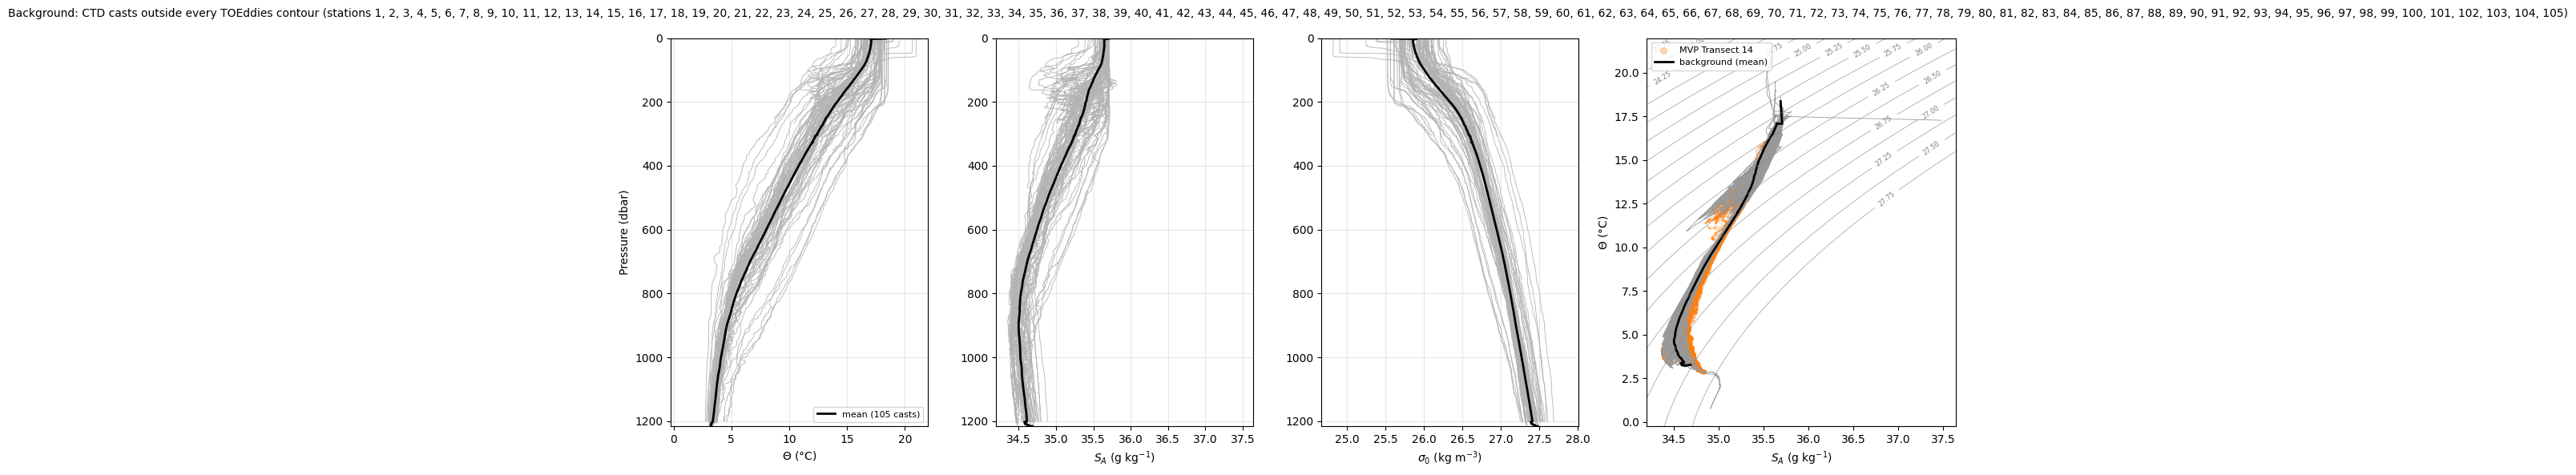

In [14]:
# ---------------- check the background profile ----------------
sig_ref_all = gsw.sigma0(SA_all, CT_all)
fig, ax = plt.subplots(1, 4, figsize=(17, 6), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.2]))
for a, data, mean, lab in [(ax[0], CT_all, ctd_ref["CT"], r"$\Theta$ (°C)"),
                           (ax[1], SA_all, ctd_ref["SA"], r"$S_A$ (g kg$^{-1}$)"),
                           (ax[2], sig_ref_all, ctd_ref["sig0"], r"$\sigma_0$ (kg m$^{-3}$)")]:
    for row in data:
        a.plot(row, p_ref, color="0.7", lw=0.6)
    a.plot(mean, ctd_ref["p"], "k", lw=2, label=f"mean ({len(ref_used)} casts)")
    a.set_xlabel(lab); a.grid(alpha=0.3)
ax[0].set_ylabel("Pressure (dbar)"); ax[0].legend(loc="lower right", fontsize=8)
for a in ax[:3]:
    a.set_ylim(ctd_ref["p"].max(), 0)

# T-S: background casts + MVP section
ax[3].scatter(sec["SA"].ravel(), sec["CT"].ravel(), s=0.3, color="tab:orange", alpha=0.3,
              label=f"MVP {transect}")
for sa_row, ct_row in zip(SA_all, CT_all):
    ax[3].plot(sa_row, ct_row, color="0.6", lw=0.6)
ax[3].plot(ctd_ref["SA"], ctd_ref["CT"], "k", lw=2, label="background (mean)")
SAg, CTg = np.meshgrid(np.linspace(*ax[3].get_xlim(), 100), np.linspace(*ax[3].get_ylim(), 100))
cs = ax[3].contour(SAg, CTg, gsw.sigma0(SAg, CTg), levels=np.arange(23.5, 28, 0.25),
                   colors="0.5", linewidths=0.4)
ax[3].clabel(cs, fmt="%.2f", fontsize=6)
ax[3].set_xlabel(r"$S_A$ (g kg$^{-1}$)"); ax[3].set_ylabel(r"$\Theta$ (°C)")
ax[3].legend(loc="upper left", fontsize=8, markerscale=10)
fig.suptitle(f"Background: CTD casts outside every TOEddies contour (stations "
             f"{', '.join(str(s) for s in ref_used['station'])})", fontsize=10)
plt.tight_layout()
plt.show()


In [15]:
# ---------------- anomaly functions (on isopycnals only) ----------------
def interp_on_rho(sigma, var, ind_rho):
    """var(sigma) -> var on the density levels ind_rho (NaN outside the sigma range).
    Sorted and de-duplicated in sigma (np.interp needs increasing x)."""
    ok = np.isfinite(sigma) & np.isfinite(var)
    if ok.sum() < 2:
        return np.full(len(ind_rho), np.nan)
    order = np.argsort(sigma[ok])
    s, idx = np.unique(sigma[ok][order], return_index=True)
    v = var[ok][order][idx]
    if s.size < 2:
        return np.full(len(ind_rho), np.nan)
    return np.interp(ind_rho, s, v, left=np.nan, right=np.nan)


def anom(ref, sec, var_name="temp", pas=0.01):
    """
    Anomalies of the MVP section relative to the background profile, ON ISOPYCNALS
    (Barabinot et al. 2025, eq. 1-2), put back at the pressure of each isopycnal in each cast:
      temp : dTheta(sigma) = Theta(sigma) - Theta*(sigma)
      sal  : dS_A(sigma)   = S_A(sigma)   - S_A*(sigma)
      disp : dp(sigma)     = p(sigma)     - p*(sigma)   isopycnal displacement (dbar),
             > 0 = isopycnal deeper than in the background (the density signal on
             isopycnals: the density anomaly itself is 0 on an isopycnal by definition)
    ref : dict(p, CT, SA, sig0) (ctd_ref).  sec : from process_transect.
    Isopycnals that do not exist in the background stay NaN (no extrapolation).
    Returns Anom with the same shape as sec["CT"] (pressure x cast).
    """
    p = sec["p"]
    sigma_grid = sec["sig0"]
    len_section = sigma_grid.shape[1]

    if var_name in ["temperature", "temp"]:
        ref_profile, var_grid = ref["CT"], sec["CT"]
    elif var_name in ["salinity", "sal"]:
        ref_profile, var_grid = ref["SA"], sec["SA"]
    elif var_name in ["disp", "displacement", "heave"]:
        ref_profile, var_grid = ref["p"], np.broadcast_to(p[:, None], sigma_grid.shape)
    else:
        raise ValueError(f"var_name must be temp, sal or disp, not {var_name!r}")

    ind_rho = np.arange(22, 28, pas)
    ref_interp = interp_on_rho(ref["sig0"], ref_profile, ind_rho)

    Anom = np.full(sigma_grid.shape, np.nan)
    for i in range(len_section):
        var_interp = interp_on_rho(sigma_grid[:, i], var_grid[:, i], ind_rho)
        Anom_rho = var_interp - ref_interp                      # anomaly on each isopycnal
        depT = interp_on_rho(sigma_grid[:, i], p, ind_rho)      # pressure of each isopycnal here

        good = np.isfinite(Anom_rho) & np.isfinite(depT)
        if good.sum() < 2:
            continue
        order = np.argsort(depT[good])
        d, idx = np.unique(depT[good][order], return_index=True)
        a = Anom_rho[good][order][idx]
        if d.size < 2:
            continue
        Anom[:, i] = np.interp(p, d, a, left=np.nan, right=np.nan)
    return Anom


In [16]:
# ---------------- figure ----------------
def plot_anomaly_section_with_map(sec, adcp, anoms, map_draw=None, map_args=None, title="",
                                  pmax=None, sig_levels=None, map_extent=None, map_pad=(2.5, 2.0),
                                  vel_lim=None, anom_lims=None, edd=None, savepath=None,
                                  flip_x=True, ref_lon=None, ref_lat=None):
    """
    Same layout as plot_section_with_map, with anomalies ON ISOPYCNALS:
                (a) Theta anomaly            (b) S_A anomaly
                (c) isopycnal displacement   (d) SADCP cross-track velocity
            small map on the right (orange = background CTD casts).
    anoms     : dict(CT=..., SA=..., disp=...) from anom(), same shape as sec["CT"].
    anom_lims : optional dict(CT=..., SA=..., disp=...) of symmetric colour limits;
                default = 99th percentile of |anomaly|.
    ref_lon, ref_lat : positions of the background casts, drawn on the map.
    Everything else is as in plot_section_with_map.
    """
    import matplotlib.patheffects as pe
    from matplotlib.gridspec import GridSpec
    try:
        import cartopy.crs as ccrs
        import cartopy.feature as cfeature
    except ImportError:
        ccrs = None

    anom_lims = anom_lims or {}
    lon, lat = sec["lon"], sec["lat"]
    xkm, p = sec["x"] / 1e3, sec["p"]
    if map_extent is None:
        map_extent = [np.nanmin(lon) - map_pad[0], np.nanmax(lon) + map_pad[0],
                      np.nanmin(lat) - map_pad[1], np.nanmax(lat) + map_pad[1]]
    sig_levels = sig_levels if sig_levels is not None else np.arange(
        np.floor(np.nanmin(sec["sig0"]) * 4) / 4, np.nanmax(sec["sig0"]), 0.25)

    fig = plt.figure(figsize=(20, 10), constrained_layout=True)
    outer = GridSpec(1, 2, figure=fig, width_ratios=[4, 1])
    gs_sec = outer[0].subgridspec(2, 2)
    gs_map = outer[1].subgridspec(2, 1, height_ratios=[1, 0.6])

    ax0 = fig.add_subplot(gs_sec[0, 0])
    axs = [ax0,
           fig.add_subplot(gs_sec[0, 1], sharex=ax0),
           fig.add_subplot(gs_sec[1, 0], sharex=ax0),
           fig.add_subplot(gs_sec[1, 1], sharex=ax0)]

    # ---- (a)-(c) anomalies on isopycnals: diverging colours, white = 0 ----
    specs = [("CT", r"$\Delta\Theta$ (°C)", r"(a) $\Theta$ anomaly on isopycnals"),
             ("SA", r"$\Delta S_A$ (g kg$^{-1}$)", r"(b) $S_A$ anomaly on isopycnals"),
             ("disp", r"$\Delta p$ (dbar)", r"(c) Isopycnal displacement ($>0$: deeper than background)")]
    for ax, (key, lab, ttl) in zip(axs[:3], specs):
        data = anoms[key]
        lim = anom_lims.get(key)
        if lim is None:
            vals = np.abs(data[np.isfinite(data)])
            lim = np.nanpercentile(vals, 99) if vals.size else 1.0
        pc = ax.pcolormesh(xkm, p, data, cmap=cmocean.cm.balance, shading="nearest",
                           vmin=-lim, vmax=lim)
        fig.colorbar(pc, ax=ax, label=lab, pad=0.01)
        ax.set_title(ttl, loc="left", fontsize=11, pad=14)

    # --- (d) SADCP cross-track velocity (unchanged) ---
    axc = axs[3]
    a_lon, a_lat, z, u, v = adcp["lon"], adcp["lat"], adcp["z"], adcp["u"], adcp["v"]
    s_m, _ = along_track_x(np.asarray(a_lon), np.asarray(a_lat),
                           sec["lon"][0], sec["lat"][0], sec["xdir"])
    s = s_m / 1e3
    ex = sec["xdir"]
    vn = -u * ex[1] + v * ex[0]        # positive = to the LEFT of the 0 km -> end direction

    edges = np.arange(np.floor(np.nanmin(s)), np.ceil(np.nanmax(s)) + DS_KM, DS_KM)
    xg, V, _ = bin_columns(s, vn, edges)
    V = fill_z_gaps(V, z)

    if vel_lim is None:
        vals = np.abs(V.ravel())
        vlim = max(0.1, np.round(np.nanpercentile(vals[np.isfinite(vals)], 98) * 10) / 10)
    else:
        vlim = vel_lim
    fill_lev = np.linspace(-vlim, vlim, N_FILL + 1)
    cf = axc.contourf(xg, z, V.T, levels=fill_lev, cmap=cmocean.cm.balance, extend="both")
    nstep = int(np.ceil(vlim / C_LINE_STEP)) + 1
    line_lev = np.round(np.arange(-nstep, nstep + 1) * C_LINE_STEP, 3)
    cs = axc.contour(xg, z, V.T, levels=line_lev, colors="k", linewidths=0.6)
    axc.clabel(cs, cs.levels, fmt="%.1f", fontsize=6, inline=True, inline_spacing=2)
    cbc = fig.colorbar(cf, ax=axc, pad=0.01)
    cbc.set_ticks(fill_lev[1::3])
    cbc.ax.set_yticklabels([f"{0.0 if abs(t) < 1e-9 else t:.2f}" for t in fill_lev[1::3]])
    cbc.set_label(r"v$_\perp$ (m s$^{-1}$)")
    axc.set_title(fr"(d) SADCP: v$_\perp$ {DS_KM:.0f} km bins", loc="left", fontsize=11, pad=14)

    edds = [edd] if isinstance(edd, dict) else list(edd or [])
    if edds:
        mark_eddies_on_sections(axs, sec, z, a_lon, a_lat, u, v, edds)

    for ax in axs:
        cs = ax.contour(xkm, p, sec["sig0"], levels=sig_levels, colors="k", linewidths=0.5)
        ax.clabel(cs, cs.levels[::2], fontsize=7, fmt="%.2f")
        ax.plot(xkm, np.zeros_like(xkm), "|", color="k", ms=6, clip_on=False)

    p_bot = pmax if pmax else np.nanmax(p)
    z_bot = pmax if pmax else np.nanmax(z)
    for ax in axs[:3]:
        ax.set_ylim(p_bot, 0)
        ax.set_ylabel("Pressure (dbar)")
    axc.set_ylim(z_bot, 0)
    axc.set_ylabel("Depth (m)")

    axs[0].set_xlim(np.nanmin(xkm), np.nanmax(xkm))
    if flip_x:
        axs[0].invert_xaxis()
    for ax in axs[:2]:
        ax.tick_params(labelbottom=False)
    for ax in axs[2:]:
        ax.tick_params(labelbottom=True)
        ax.set_xlabel("Along-track distance from start (km)")

    # ======================= map (small, right) =======================
    if ccrs is not None:
        crs = ccrs.PlateCarree()
        proj = ccrs.Mercator(central_longitude=np.mean(map_extent[:2]))
        axm = fig.add_subplot(gs_map[0], projection=proj)
        axm.set_extent(map_extent, crs=crs)
        tr = dict(transform=crs)
    else:
        crs, tr = None, {}
        axm = fig.add_subplot(gs_map[0])
        axm.set_xlim(map_extent[:2]); axm.set_ylim(map_extent[2:])
        axm.set_aspect(1 / np.cos(np.deg2rad(np.mean(map_extent[2:]))))

    if map_draw is not None:
        map_draw(axm, crs, *(map_args or []))

    if ccrs is not None:
        axm.add_feature(cfeature.LAND, facecolor="0.8", zorder=50)
        axm.coastlines(resolution="50m", linewidth=0.6, zorder=51)
        gl = axm.gridlines(crs=crs, draw_labels=True, linewidth=0.4, color="0.5",
                           alpha=0.4, linestyle="--")
        gl.top_labels = gl.right_labels = False
        gl.xlabel_style = gl.ylabel_style = {"size": 8}
    else:
        axm.grid(lw=0.4, alpha=0.4, ls="--")
        axm.tick_params(labelsize=8)

    halo = [pe.Stroke(linewidth=4.5, foreground="white"), pe.Normal()]
    axm.plot(lon, lat, "-", color="k", lw=2, path_effects=halo, zorder=100, **tr)
    if ref_lon is not None and len(ref_lon):
        axm.scatter(ref_lon, ref_lat, s=25, color="orange", edgecolor="k", linewidth=0.5,
                    zorder=101, **tr)
    for i, lab in [(0, "0 km"), (-1, f"{xkm[-1]:.0f} km")]:
        axm.plot(lon[i], lat[i], marker="o" if i == 0 else "s", ms=6, mfc="yellow",
                 mec="k", mew=1, zorder=102, **tr)
        axm.annotate(lab, (lon[i], lat[i]), xytext=(6, 0), textcoords="offset points",
                     fontsize=8, fontweight="bold", va="center", zorder=103,
                     path_effects=[pe.withStroke(linewidth=2.5, foreground="white")],
                     xycoords=crs._as_mpl_transform(axm) if crs is not None else "data")
    t0 = sec["time"][0].strftime("%Y-%m-%d %H:%M")
    t1 = sec["time"][-1].strftime("%Y-%m-%d %H:%M")
    axm.set_title(f"{t0}\nto {t1} UTC", fontsize=9)

    fig.suptitle(title, fontsize=14, fontweight="bold")
    if savepath:
        fig.savefig(savepath, dpi=300, bbox_inches="tight")
    return fig, [axm] + axs


CT    anomaly: -1.909 .. +1.598, 86% of the section filled
SA    anomaly: -0.486 .. +0.249, 86% of the section filled
disp  anomaly: -640.369 .. +64.051, 86% of the section filled
  C: Nencioli center at 272 km, outside section -> not marked


/var/folders/lg/5krm8xnn5xv0smms_psmknp40000gn/T/ipykernel_91445/3309952731.py:55: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = ax.pcolormesh(xkm, p, data, cmap=cmocean.cm.balance, shading="nearest",


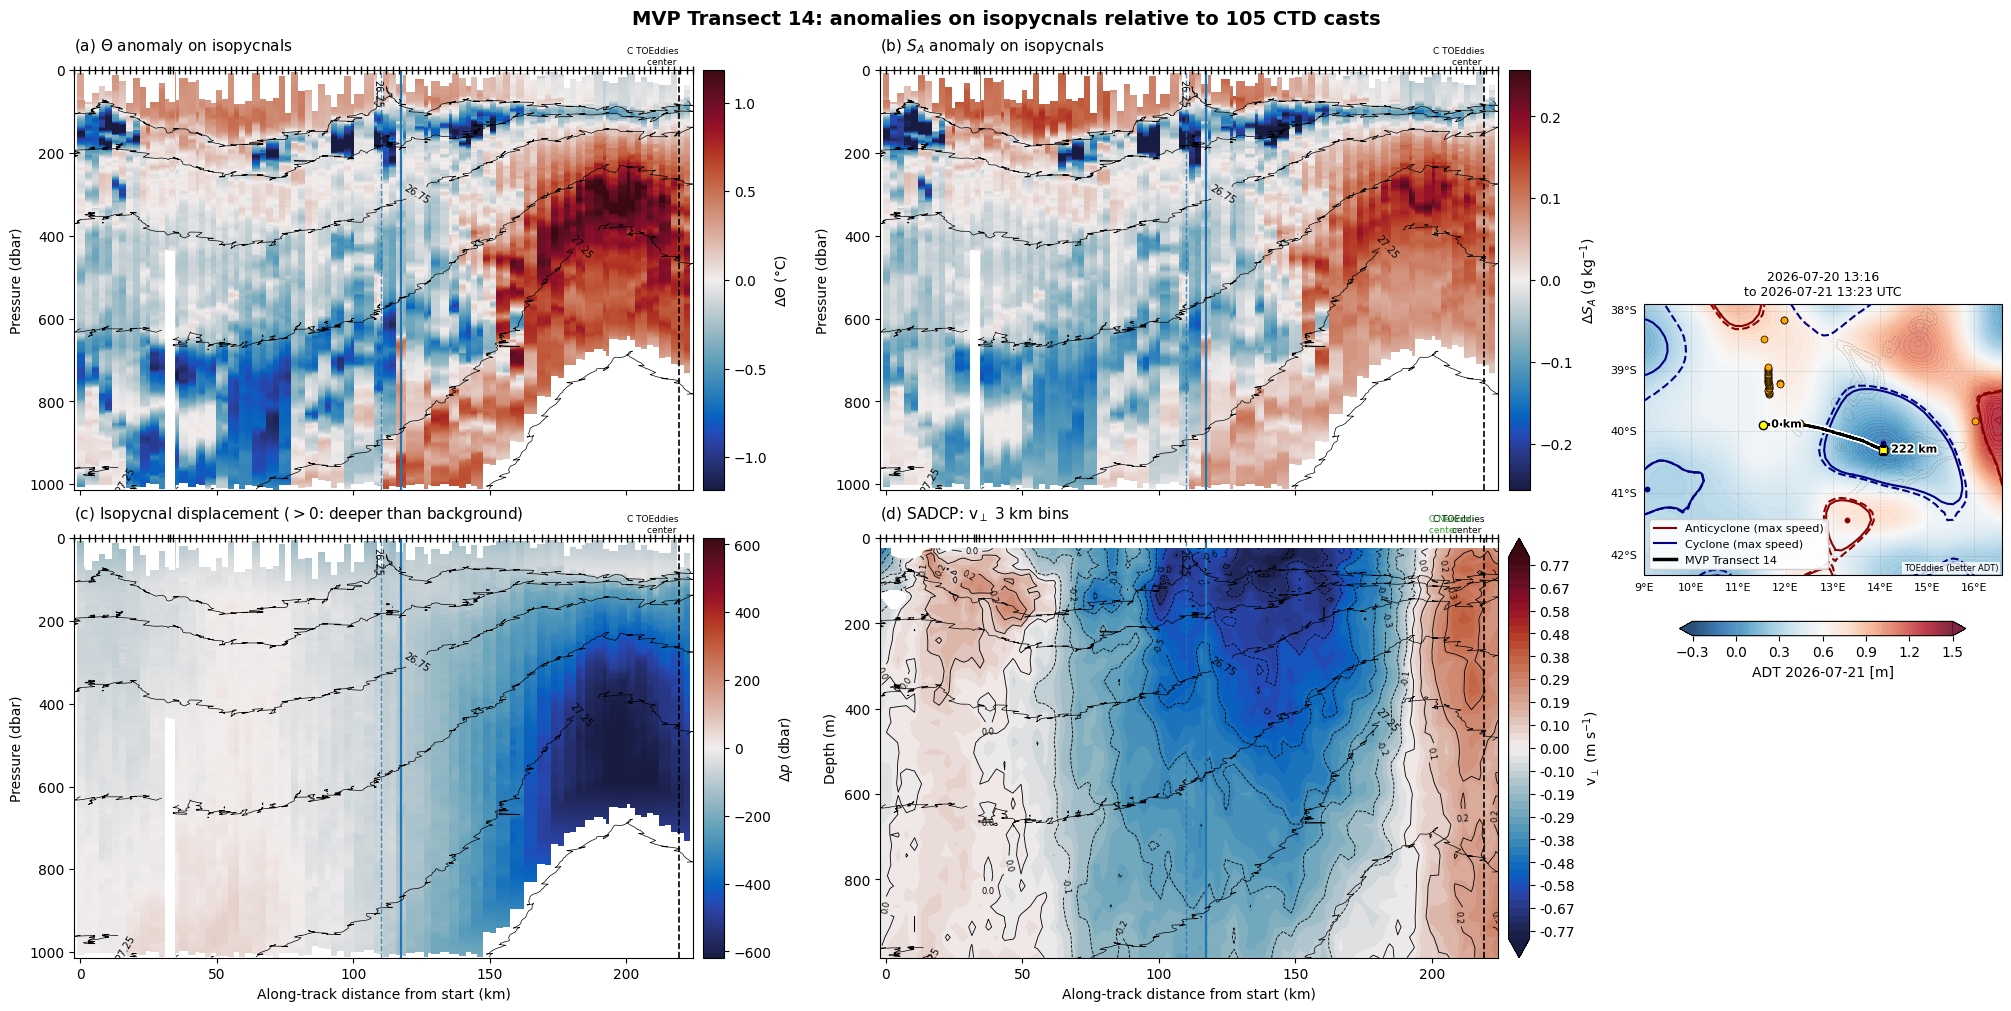

In [17]:
# ---------------- run ----------------
anoms = dict(CT=anom(ctd_ref, sec, "temp"),
             SA=anom(ctd_ref, sec, "sal"),
             disp=anom(ctd_ref, sec, "disp"))
for k, a in anoms.items():
    print(f"{k:5s} anomaly: {np.nanmin(a):+.3f} .. {np.nanmax(a):+.3f}, "
          f"{np.isfinite(a).mean() * 100:.0f}% of the section filled")

fig, axs = plot_anomaly_section_with_map(
    sec, sadcp_mvp_processed, anoms,
    map_draw=draw_background, map_args=args,
    title=f"MVP {transect}: anomalies on isopycnals relative to {len(ref_used)} CTD casts",
    edd=edds, flip_x=invert_x, vel_lim=0.8,
    ref_lon=ref_used["lon"].values, ref_lat=ref_used["lat"].values,
    savepath=out_dir + f"{transect}_section_anomalies_ctdref_adcp")
plt.show()
